# NBA Player Impact Analysis

# Pipeline:
# data.py → metrics.py → viz.py

In [25]:
from src.data import get_player_id, get_career_stats
from src.metrics import add_per_game_stats, add_all_around_score
from src.viz import plot_top5_score
import pandas as pd

In [26]:
names = [
    'LeBron James',
    'Stephen Curry',
    'Luka Dončić',
    'Giannis Antetokounmpo',
    'Nikola Jokić'
]

In [27]:
results = []

for name in names:
    player_id = get_player_id(name)

    if player_id is None:
        continue

    df = get_career_stats(player_id)

    summary = {
        "Player": name,
        "PTS": df['PTS'].sum(),
        "AST": df['AST'].sum(),
        "REB": df['REB'].sum(),
        "GP": df['GP'].sum()
    }

    results.append(summary)

results_df = pd.DataFrame(results)
results_df

,Player,PTS,AST,REB,GP
0,LeBron James,43440,12016,12095,1622
1,Stephen Curry,26528,6743,4973,1069
2,Luka Dončić,16429,4613,4785,564
3,Giannis Antetokounmpo,21531,4484,8882,895
4,Nikola Jokić,18009,6080,8977,810


In [28]:
results_df = add_per_game_stats(results_df)
results_df = add_all_around_score(results_df)
results_df.sort_values(by='ALL_AROUND_SCORE', ascending=False)

,Player,PTS,AST,REB,GP,PPG,APG,RPG,ALL_AROUND_SCORE
2,Luka Dončić,16429,4613,4785,564,29.129433,8.179078,8.484043,18.715248
0,LeBron James,43440,12016,12095,1622,26.781751,7.408138,7.456843,17.104686
4,Nikola Jokić,18009,6080,8977,810,22.233333,7.506173,11.082716,15.585062
3,Giannis Antetokounmpo,21531,4484,8882,895,24.056983,5.010056,9.924022,15.516313
1,Stephen Curry,26528,6743,4973,1069,24.815716,6.307764,4.652011,15.230589


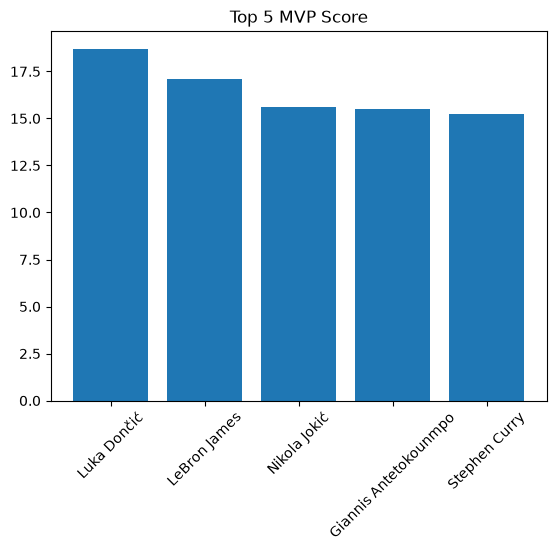

In [29]:
plot_top5_score(results_df)